# Issue #345 — paired value selector × fixed R3

Executed analysis notebook. The issue is the independent evaluation unit.

In [1]:
from pathlib import Path
import json
import pandas as pd
candidates=[Path.cwd(), *Path.cwd().parents]
root=next((p for p in candidates if (p/'results/paired_value_r3_n7').exists()), None)
if root is None: raise FileNotFoundError('paired value package not found')
package=root/'results/paired_value_r3_n7'
decision=json.loads((package/'decision.json').read_text())
decision

{'candidate_selectors': [],
 'contract': 'BJ-UNIFIED-PAIRED-VALUE-R3-N7-001/v1',
 'historical_only': True,
 'issue': 345,
 'modifies_218': False,
 'payout_factor_application': 'ticket_level_once',
 'promotable_to_210': False,
 'proxy_grade': 'RETROSPECTIVE_RELATIVE_PROXY',
 'replacement_issues': 119,
 'replacement_rows': 3201,
 'selector_diagnostics': [{'action_fraction_of_frozen_issues': 1.0,
   'action_issues': 119,
   'ex_largest_lift_positive_both_years': False,
   'raw_lift_positive_both_years': False,
   'selector': 'POINT'},
  {'action_fraction_of_frozen_issues': 1.0,
   'action_issues': 119,
   'ex_largest_lift_positive_both_years': False,
   'raw_lift_positive_both_years': False,
   'selector': 'P50'},
  {'action_fraction_of_frozen_issues': 1.0,
   'action_issues': 119,
   'ex_largest_lift_positive_both_years': False,
   'raw_lift_positive_both_years': False,
   'selector': 'P60'},
  {'action_fraction_of_frozen_issues': 0.9915966386554622,
   'action_issues': 118,
   'ex_large

## Data completeness and paired calibration

In [2]:
coverage=pd.read_csv(package/'settlement_coverage_ledger.csv',dtype={'issue':str})
pairs=pd.read_parquet(package/'pair_calibration.parquet')
pair_receipt=json.loads((package/'pair_calibration_receipt.json').read_text())
display(coverage.groupby(['status','reason']).size().rename('issues'))
display(pairs.groupby('issue').agg(rows=('issue','size'),weight=('issue_weight','sum')).describe())
pair_receipt

status    reason              
EXCLUDED  missing_match_label      5
          untrusted_settlement    18
INCLUDED  included                96
Name: issues, dtype: int64

,rows,weight
count,62.000000,6.200000e+01
mean,522.419355,1.612903e-02
std,309.660181,9.932998e-19
min,42.000000,1.612903e-02
25%,258.750000,1.612903e-02
50%,451.000000,1.612903e-02
75%,741.250000,1.612903e-02
max,1188.000000,1.612903e-02


{'calibration_issues': 62,
 'calibration_year': 2022,
 'candidate_definition': 'outside_retained_mass_top7',
 'contract': 'BJ-UNIFIED-PAIRED-VALUE-R3-N7-001/v1',
 'each_issue_total_weight': 0.016129032258064516,
 'fit_through_year': 2021,
 'incumbent_definition': 'retained_mass_top7',
 'max_retained_mass_drop': 0.05,
 'pair_calibration_frame_sha256': '3059a1cb9401d0f39f70a3e2533db6a9ccd524209d56d1ff708385ce6ee41e51',
 'pair_rows': 32390,
 'paired_residual_q10': -0.09096526489476606,
 'probability_source_sha256': '5ae5bb5ebcb56c10fdfb27ef624c5b34d8b89cc04ddc4dcbbde478e5af84855e',
 'proxy_grade': 'RETROSPECTIVE_RELATIVE_PROXY',
 'same_issue_pairs_only': True,
 'settlement_source_sha256': '7f62079b18b3c028884da92aa8393f5b198246c9d7c32cd0b401562a055c5d6f',
 'total_weight': 1.0}

## Replacement curve and matched performance

In [3]:
replacements=pd.read_parquet(package/'replacement_ledger.parquet')
performance=pd.read_csv(package/'performance.csv')
contrasts=pd.read_csv(package/'contrasts.csv')
display(replacements.groupby(['selector','issue_year']).agg(rows=('step','size'),issues=('issue','nunique')) if len(replacements) else 'No replacements')
display(performance[(performance.cell.str.endswith('R3A0'))])
display(contrasts[contrasts.contrast.str.endswith('_UNDER_R3')])

rows  issues
selector issue_year              
P50      2023         321      53
         2024         390      66
P60      2023         298      53
         2024         349      66
P70      2023         257      52
         2024         293      66
P80      2023         191      52
         2024         203      66
PAIR_L10 2023          86      45
         2024         102      55
POINT    2023         321      53
         2024         390      66

,cell,period,issues,stake_cny,gross_cny,pnl_cny,ending_capital_cny,capital_return,stake_roi,hit_issues,hit_rate,miss_by_1,miss_by_2,mean_replacements
3,P50R3A0,2023,41,41984,53082.544325,11098.544325,111098.544325,0.110985,0.264352,5,0.121951,14,13,6.097561
4,P50R3A0,2024,55,56320,30112.472110,-26207.527890,73792.472110,-0.262075,-0.465333,5,0.090909,26,13,5.890909
5,P50R3A0,ALL,96,98304,83195.016435,-15108.983565,84891.016435,-0.151090,-0.153697,10,0.104167,40,26,5.979167
9,P60R3A0,2023,41,41984,51938.280118,9954.280118,109954.280118,0.099543,0.237097,6,0.146341,12,17,5.658537
10,P60R3A0,2024,55,56320,48270.820194,-8049.179806,91950.820194,-0.080492,-0.142919,6,0.109091,24,18,5.181818
11,P60R3A0,ALL,96,98304,100209.100312,1905.100312,101905.100312,0.019051,0.019380,12,0.125000,36,35,5.385417
15,P70R3A0,2023,41,41984,59782.098178,17798.098178,117798.098178,0.177981,0.423926,9,0.219512,12,13,4.878049
16,P70R3A0,2024,55,56320,51846.302211,-4473.697789,95526.302211,-0.044737,-0.079434,6,0.109091,26,17,4.436364
17,P70R3A0,ALL,96,98304,111628.400389,13324.400389,113324.400389,0.133244,0.135543,15,0.156250,38,30,4.625000
21,P80R3A0,2023,41,41984,16788.223567,-25195.776433,74804.223567,-0.251958,-0.600128,5,0.121951,13,13,3.658537


,contrast,challenger,control,period,issues,lift_cny,ex_largest_lift_cny,bootstrap_p05_cny,bootstrap_p50_cny,bootstrap_p95_cny,bootstrap_positive_fraction
1,POINT_UNDER_R3,POINTR3A0,S0R3A0,2023,41,-36959.400413,23978.981698,-158002.698227,-27868.754753,56882.938836,0.3365
4,P50_UNDER_R3,P50R3A0,S0R3A0,2023,41,-36959.400413,23978.981698,-161450.768621,-31401.437931,60626.215426,0.3170
7,P60_UNDER_R3,P60R3A0,S0R3A0,2023,41,-38103.664619,22834.717492,-165669.725788,-32184.492936,56027.599227,0.3100
10,P70_UNDER_R3,P70R3A0,S0R3A0,2023,41,-30259.846559,30678.535551,-156748.514328,-23895.525343,57218.551624,0.3700
13,P80_UNDER_R3,P80R3A0,S0R3A0,2023,41,-73253.721170,-12315.339059,-188310.729158,-67671.869691,2669.300578,0.0660
16,PAIR_L10_UNDER_R3,PAIR_L10R3A0,S0R3A0,2023,41,-50959.031614,9979.350497,-171165.275630,-45020.310785,24441.787566,0.3025
26,POINT_UNDER_R3,POINTR3A0,S0R3A0,2024,55,-110360.901699,-73046.376124,-207829.336681,-106273.303404,-23588.387228,0.0140
29,P50_UNDER_R3,P50R3A0,S0R3A0,2024,55,-110360.901699,-73046.376124,-215445.571037,-104611.301828,-23501.573960,0.0095
32,P60_UNDER_R3,P60R3A0,S0R3A0,2024,55,-92202.553616,-54888.028041,-198613.801265,-87733.833371,-3899.896824,0.0415
35,P70_UNDER_R3,P70R3A0,S0R3A0,2024,55,-88627.071598,-51312.546023,-191799.519911,-86010.556106,5371.842654,0.0610


## Continuous capital and holding risk

,cell,period,max_drawdown_fraction,max_consecutive_losing_issues,worst_rolling_5_cny,worst_rolling_10_cny,worst_rolling_20_cny,max_completed_recovery_issues,terminal_underwater_issues,largest_payout_share,payout_hhi
5,P50R3A0,ALL,0.312352,23,-5120,-10240.0,-20480.000000,16,53,0.249435,0.151337
11,P60R3A0,ALL,0.185253,16,-5120,-10240.0,-15423.303044,32,42,0.169132,0.106459
17,P70R3A0,ALL,0.135370,13,-5120,-10240.0,-12593.325040,16,42,0.151830,0.091660
23,P80R3A0,ALL,0.497904,27,-5120,-10240.0,-19971.816323,0,96,0.230122,0.138506
29,PAIR_L10R3A0,ALL,0.289423,18,-5120,-10240.0,-17005.903893,76,3,0.496174,0.267443
35,POINTR3A0,ALL,0.312352,23,-5120,-10240.0,-20480.000000,16,53,0.249435,0.151337
41,S0R3A0,ALL,0.174562,19,-5120,-10240.0,-15989.363238,74,1,0.264357,0.135548


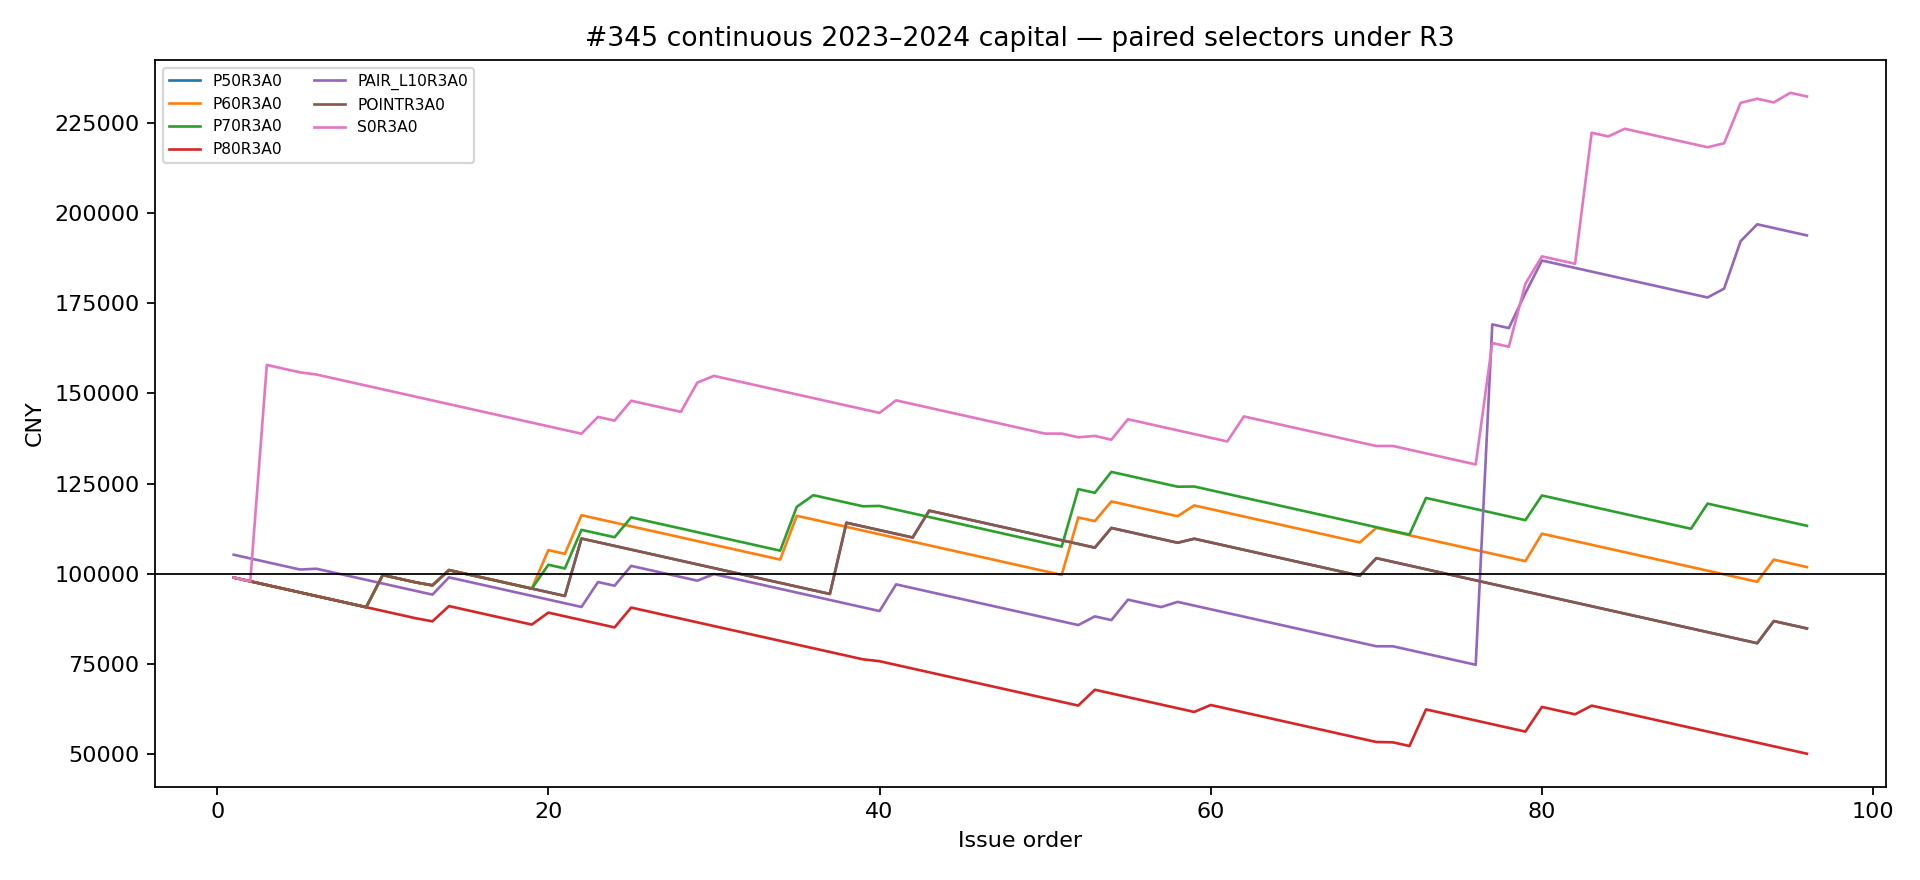

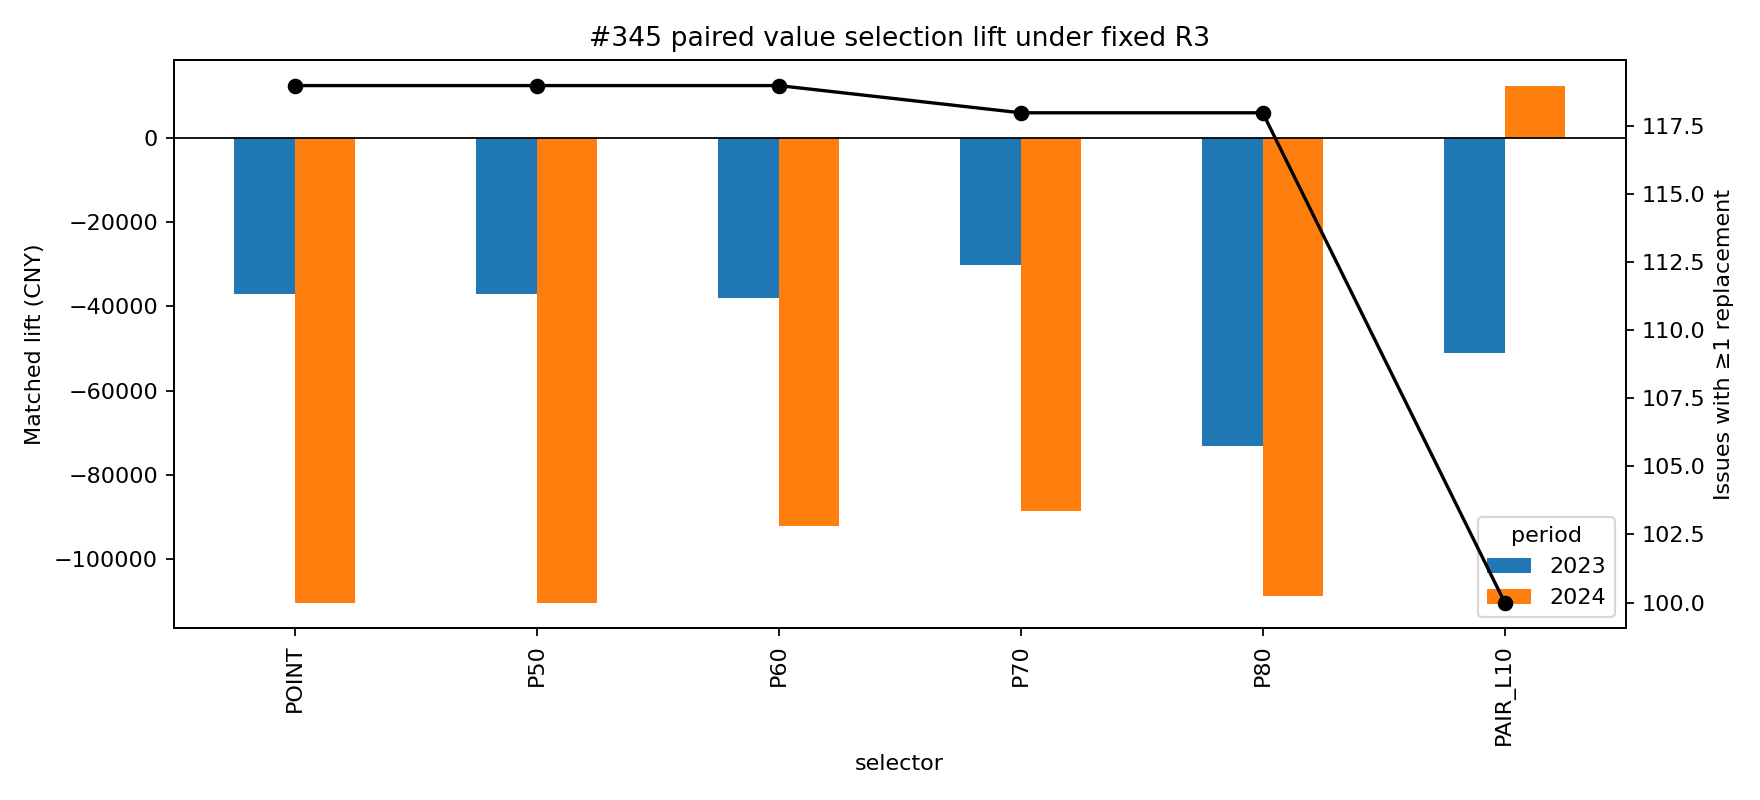

In [4]:
risk=pd.read_csv(package/'risk_diagnostics.csv')
display(risk[(risk.period.astype(str)=='ALL') & risk.cell.str.endswith('R3A0')])
from IPython.display import Image, display
display(Image(filename=str(root/'docs/research/figures/issue_345_paired_value_capital.png')))
display(Image(filename=str(root/'docs/research/figures/issue_345_paired_value_curve.png')))

## Boundary

The 10h surface is a retrospective relative proxy. No historical result here unlocks #210 or changes #218.